# Who are US hospitals hiring? One week of postings from 67 health systems

This notebook explores the [US Hospital Job Postings with Pay](https://www.kaggle.com/datasets/dhughes6071/us-hospital-job-postings-with-pay-oct-2026)
sample: every job posted between 10 and 17 October 2026 on the career sites of 67 large US health systems.

It answers five questions a staffing or recruiting team would ask:

1. Which health systems are posting the most roles?
2. What roles are they hiring for?
3. Who states pay, and what is typical?
4. Full time, part time or per diem?
5. Where are the jobs?

This is one week of *new postings*, not everything open, so it shows who is hiring right now rather than total
headcount needs.

In [1]:
import glob
import re
import pandas as pd
import matplotlib.pyplot as plt

# On Kaggle the file sits under /kaggle/input; elsewhere, next to the notebook.
path = (glob.glob("/kaggle/input/**/us-hospital-jobs-sample-*.csv", recursive=True)
        or glob.glob("us-hospital-jobs-sample-*.csv"))[0]
jobs = pd.read_csv(path, parse_dates=["posted_at"], keep_default_na=False, na_values=[""])
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})
jobs[["title", "health_system", "location", "employment_type", "posted_at", "salary_min", "salary_max", "salary_period"]].head()

,title,health_system,location,employment_type,posted_at,salary_min,salary_max,salary_period
0,RN - Med Cardiovascular Part-time Day,Providence,"Torrance, CA, United States",Part time,2026-10-17,NaN,NaN,NaN
1,New Grad RN - Labor and Delivery - Duke Univer...,Duke University Health System,"Durham, North Carolina, United States",Full Time,2026-10-17,NaN,NaN,NaN
2,Patient Access Representative,Adventist Health,"Visalia, CA, United States",NaN,2026-10-17,NaN,NaN,NaN
3,Patient Access Representative (Full-time regul...,Adventist Health,"Glendale, CA, United States",Full time,2026-10-17,NaN,NaN,NaN
4,Patient Access Representative (Full-time regul...,Adventist Health,"Hanford, CA, United States",Full time,2026-10-17,NaN,NaN,NaN


In [2]:
print(f"{len(jobs):,} jobs at {jobs['health_system'].nunique()} health systems")
print(f"{jobs['title'].nunique():,} different job titles")
print(f"{jobs['salary_period'].notna().sum():,} jobs ({jobs['salary_period'].notna().mean():.0%}) state their pay")
jobs["posted_at"].dt.day_name().value_counts().to_frame("jobs")

17,557 jobs at 67 health systems
13,493 different job titles
5,757 jobs (33%) state their pay


,jobs
posted_at,
Wednesday,3637
Thursday,3583
Tuesday,3510
Friday,3273
Monday,3191
Saturday,256
Sunday,107


## 1. Who is posting the most?

Big systems post more simply because they are big, so the table also divides by `system_beds`. Bed counts cover
hospitals only (AHRQ, 2023), while postings also include clinics and offices, so treat the ratio as a rough guide.

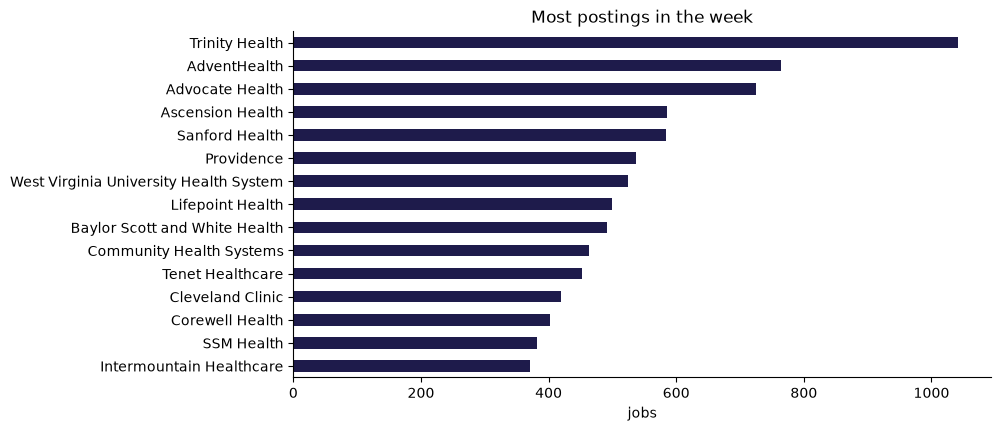

The top 10 systems account for 35% of postings


,jobs,beds,jobs_per_100_beds
health_system,,,
Sanford Health,584,1925,30.3
West Virginia University Health System,525,2370,22.2
Sharp Healthcare,329,1601,20.5
Allina Health,322,1759,18.3
Rochester Regional Health System,177,1057,16.7
Vanderbilt Health,199,1292,15.4
Henry Ford Health,261,1787,14.6
Multicare Health System,214,1536,13.9
Northwestern Medicine,316,2272,13.9


In [3]:
ax = jobs["health_system"].value_counts().head(15).sort_values().plot.barh(color="#1e1b4b")
ax.set_title("Most postings in the week"); ax.set_xlabel("jobs"); ax.set_ylabel("")
plt.show()

print(f"The top 10 systems account for {jobs['health_system'].value_counts().head(10).sum() / len(jobs):.0%} of postings")
systems = jobs.groupby("health_system").agg(jobs=("url", "size"), beds=("system_beds", "first"))
systems["jobs_per_100_beds"] = (systems["jobs"] / systems["beds"] * 100).round(1)
systems[systems["jobs"] >= 100].sort_values("jobs_per_100_beds", ascending=False).head(10)

Trinity Health, AdventHealth and Advocate Health post the most, but relative to size Sanford Health leads
at about 30 postings per 100 beds, well ahead of the giants.

## 2. What roles?

Titles are written differently everywhere, so exact counts only go so far:

In [4]:
jobs["title"].value_counts().head(15).to_frame("jobs")

,jobs
title,
Medical Assistant,79
Patient Care Technician,58
Security Officer,58
Cook,47
Registered Nurse,47
CT Technologist,44
Phlebotomist,43
Certified Medical Assistant,42
Housekeeper,37


Grouping titles by keyword gives a clearer picture. The rules run in order and the first match wins, so
"Nurse Manager" counts as leadership and "Nursing Assistant" as support. They are deliberately simple and will miss
some titles.

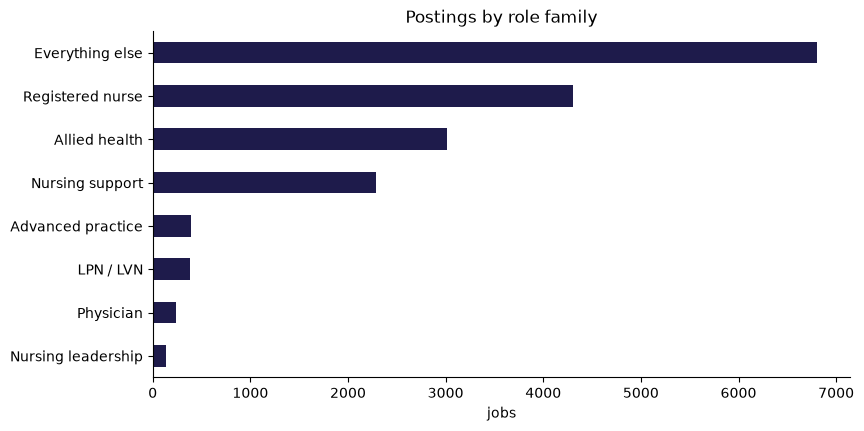

,% of jobs
role_family,
Everything else,38.8
Registered nurse,24.5
Allied health,17.2
Nursing support,13.0
Advanced practice,2.2
LPN / LVN,2.2
Physician,1.3
Nursing leadership,0.7


In [5]:
FAMILIES = [
    ("Nursing leadership", r"(?i)nurse manager|nursing (director|supervisor|manager)|director,? (of )?nursing|chief nursing|nurse (director|supervisor)"),
    ("Advanced practice", r"(?i)nurse (practitioner|anesthetist|midwife)|physician assistant|advanced practice|\b(?-i:APRN|NP|FNP|CRNA|CRNP|PA-C)\b"),
    ("Registered nurse", r"(?i)registered nurse|\b(?-i:RN|BSN)\b"),
    ("LPN / LVN", r"(?i)licensed (practical|vocational) nurse|\b(?-i:LPN|LVN)\b"),
    ("Nursing support", r"(?i)nurs(e|ing) (aide|assistant|tech)|patient care (tech|assistant|associate)|medical assistant|\b(?-i:CNA|PCT|PCA|CMA)\b"),
    # "Physician Office Coordinator" and "Physician Services Coder" are not physicians.
    ("Physician", r"(?i)^(?!.*(coder|coding|billing|analyst|coordinator|office|practice|manager|supervisor|specialist|representative|\brep\b|assistant|technician|contracts|compensation|referral|scheduler|recruiter|liaison|credentialing)).*(physician|hospitalist|surgeon|anesthesiologist|psychiatrist|radiologist|\b(?-i:MD)\b)"),
    ("Allied health", r"(?i)therap|radiolog|technologist|sonograph|phlebotom|laborator|pharmac|surgical tech|sterile|respiratory|paramedic|social work|dietitian|case manag"),
]

def family(title):
    for name, pattern in FAMILIES:
        if re.search(pattern, title):
            return name
    return "Everything else"

jobs["role_family"] = jobs["title"].map(family)
ax = jobs["role_family"].value_counts().sort_values().plot.barh(color="#1e1b4b")
ax.set_title("Postings by role family"); ax.set_xlabel("jobs"); ax.set_ylabel("")
plt.show()
(jobs["role_family"].value_counts(normalize=True) * 100).round(1).to_frame("% of jobs")

Registered nurses are about a quarter of postings (24.5%). "Everything else" (38.8%) includes the
non-clinical staff a hospital also needs, such as food service, security and administration, plus titles the rules miss.

## 3. Pay

Stating pay is far from universal, and it depends heavily on the employer:

25 of 67 systems state no pay at all


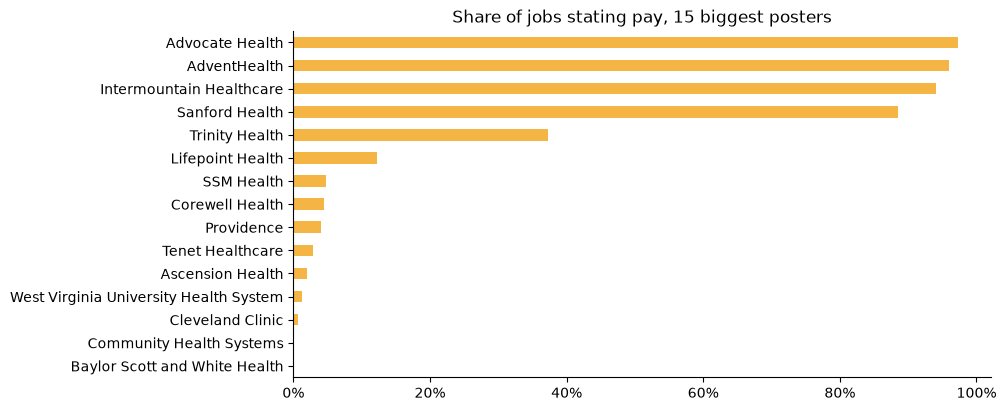

In [6]:
by_system = jobs.groupby("health_system").agg(jobs=("url", "size"), share_with_pay=("salary_period", lambda s: s.notna().mean()))
print(f"{(by_system['share_with_pay'] == 0).sum()} of {len(by_system)} systems state no pay at all")
top = by_system.sort_values("jobs", ascending=False).head(15).sort_values("share_with_pay")
ax = top["share_with_pay"].plot.barh(color="#f4b544")
ax.set_title("Share of jobs stating pay, 15 biggest posters"); ax.set_ylabel("")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.show()

25 of the 67 systems state no pay at all, so every pay figure below describes the employers that publish it,
not all hospitals.

**Two checks before using the pay columns.** This is worth doing with any scraped pay data.

- A few Cleveland Clinic jobs are in London and paid in pounds, so we keep USD only.
- Sharp Healthcare's figures are wrong in this file. Its postings give hourly pay with three decimals
  (`$26.320 - $32.890 - $36.830`, as minimum, midpoint and maximum), and the collector read that as \$26,320 a year, with
  the midpoint in `salary_max`. The tell is below: its registered nurses appear to earn far less a year than those at
  other systems. We set those rows aside rather than try to repair them, because the true maximum isn't in the file.

In [7]:
rn_yearly = jobs[(jobs["role_family"] == "Registered nurse") & (jobs["salary_period"] == "year") & (jobs["salary_currency"] == "USD")]
display(rn_yearly.groupby(rn_yearly["health_system"] == "Sharp Healthcare")[["salary_min", "salary_max"]].median()
        .rename_axis("Sharp Healthcare?").round(0))

pay = jobs[(jobs["salary_currency"] == "USD") & (jobs["health_system"] != "Sharp Healthcare")].copy()
print(f"{len(pay):,} jobs with usable USD pay, from {pay['health_system'].nunique()} systems")
pay.groupby("salary_period").agg(jobs=("url", "size"), median_min=("salary_min", "median"), median_max=("salary_max", "median")).round(2)

,salary_min,salary_max
Sharp Healthcare?,,
False,89066.0,136469.0
True,64210.0,72970.0


5,448 jobs with usable USD pay, from 40 systems


,jobs,median_min,median_max
salary_period,,,
hour,4906,26.01,38.39
year,542,106059.20,153220.00


Medians rather than averages, because a few physician packages would drag an average up. Annual postings lean
towards salaried and senior roles, so don't compare the two rows directly. Splitting by role is more useful (groups of
at least 30 jobs):

In [8]:
hourly = pay[pay["salary_period"] == "hour"]
def pay_table(rows, by, at_least=30):
    table = rows.groupby(by).agg(jobs=("url", "size"), median_min=("salary_min", "median"), median_max=("salary_max", "median")).round(2)
    return table[table["jobs"] >= at_least].sort_values("median_min", ascending=False)

hourly = pay[pay["salary_period"] == "hour"]
display(pay_table(hourly, "role_family"))
pay_table(pay[pay["salary_period"] == "year"], "role_family")

,jobs,median_min,median_max
role_family,,,
Advanced practice,54,57.49,82.35
Registered nurse,1172,38.20,57.30
Allied health,881,31.34,46.05
LPN / LVN,143,24.10,36.00
Everything else,1869,20.32,29.06
Nursing support,761,19.80,27.94


,jobs,median_min,median_max
role_family,,,
Physician,50,300831.5,351000.0
Advanced practice,53,135720.0,173867.2
Allied health,51,96720.0,133369.6
Everything else,308,93880.8,139048.0
Registered nurse,64,89065.5,136468.8


For anyone placing nurses, the same employer type can pay very differently. Here are hourly registered nurse
postings by health system, and short-term contract or travel roles against everything else.

In [9]:
rn = hourly[hourly["role_family"] == "Registered nurse"]
print(f"{len(rn):,} hourly RN postings: median range ${rn['salary_min'].median():.2f} to ${rn['salary_max'].median():.2f}")
contract = rn["title"].str.contains(r"(?i)\bcontract\b|\btravel(?:er|ing)?\b") | rn["employment_type"].fillna("").str.contains(r"(?i)contract|temporary")
display(pay_table(rn.assign(kind=contract.map({True: "Contract / travel", False: "Staff"})), "kind", at_least=1))
pay_table(rn, "health_system", at_least=20)

1,172 hourly RN postings: median range $38.20 to $57.30


,jobs,median_min,median_max
kind,,,
Contract / travel,51,63.0,66.0
Staff,1121,38.0,57.3


,jobs,median_min,median_max
health_system,,,
Sutter Health,29,78.31,109.62
Multicare Health System,44,48.15,90.83
Virtua Health,35,46.31,60.44
Allina Health,122,44.64,74.33
Sentara Healthcare,21,41.93,61.01
Trinity Health,108,40.00,59.92
UMass Memorial Health Care,23,39.89,79.52
Mass General Brigham,24,39.27,94.69
Rochester Regional Health System,24,38.67,51.92


The typical hourly registered nurse range is \$38.20 to \$57.30. Contract and travel roles start much higher
(about \$63), though that rests on only 51 postings from three employers. Between systems the gap is wide: the
median starting rate runs from \$32.00 at Sanford Health to \$78.31 at Sutter Health. Local cost of living probably explains
much of that, as Sutter is in California. Sharp Healthcare is missing here because of the check above.

## 4. Full time, part time or per diem?

`employment_type` is spelled many ways, so we tidy it first. Many per diem roles only say so in the title, so a role
counts as per diem if either field says it.

Per diem by the employment_type field alone: 312


Per diem by title or field: 1,562


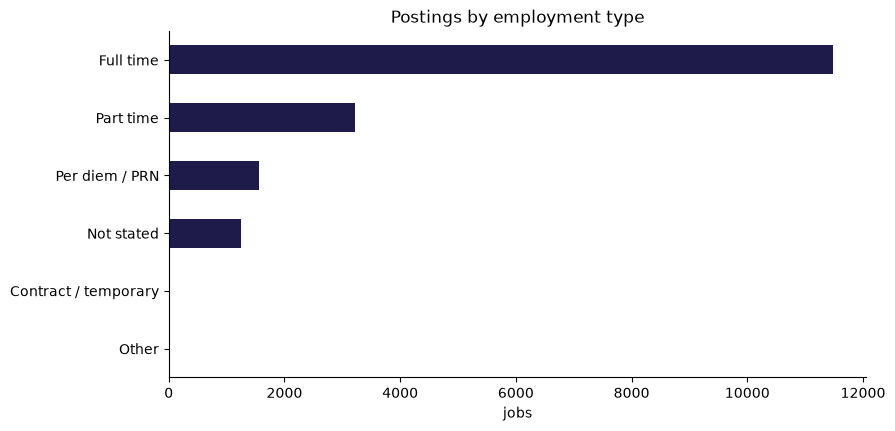

,jobs
employment,
Full time,11481
Part time,3226
Per diem / PRN,1562
Not stated,1254
Contract / temporary,23
Other,11


,% of family that is per diem
role_family,
Allied health,14.9
Registered nurse,9.8
Everything else,7.2
Advanced practice,6.6
Nursing support,6.0
LPN / LVN,5.5
Physician,4.7
Nursing leadership,2.3


In [10]:
def employment(row):
    kind = str(row["employment_type"]).strip().lower().replace("-", " ")
    if re.search(r"(?i)per[\s-]?diem", row["title"]) or re.search(r"\bPRN\b", row["title"]) or kind in ("prn", "per diem"):
        return "Per diem / PRN"
    if pd.isna(row["employment_type"]):
        return "Not stated"
    return {"full time": "Full time", "part time": "Part time", "contract": "Contract / temporary",
            "temporary": "Contract / temporary"}.get(kind, "Other")

jobs["employment"] = jobs.apply(employment, axis=1)
print(f"Per diem by the employment_type field alone: {jobs['employment_type'].fillna('').str.contains(r'(?i)per diem|prn').sum():,}")
print(f"Per diem by title or field: {(jobs['employment'] == 'Per diem / PRN').sum():,}")
ax = jobs["employment"].value_counts().sort_values().plot.barh(color="#1e1b4b")
ax.set_title("Postings by employment type"); ax.set_xlabel("jobs"); ax.set_ylabel("")
plt.show()

display(jobs["employment"].value_counts().to_frame("jobs"))
(jobs.groupby("role_family")["employment"].apply(lambda s: (s == "Per diem / PRN").mean()) * 100).round(1).sort_values(ascending=False).to_frame("% of family that is per diem")

The title matters: the `employment_type` field alone finds 312 per diem roles, while adding titles finds 1,562,
five times as many. Per diem is most common in allied health (14.9%) and among registered nurses (9.8%).

## 5. Where are the jobs?

`system_state` is the health system's *home* state, and big systems hire across many states, so it can't tell you
where a job is. `location` can, but it is free text ("Boston-MA", "SD, Sioux Falls", "Memorial Hospital West"). This
pulls out a state where one is written, and leaves the rest blank rather than guessing.

State found for 68% of jobs


Of those, 32% are outside the system's home state


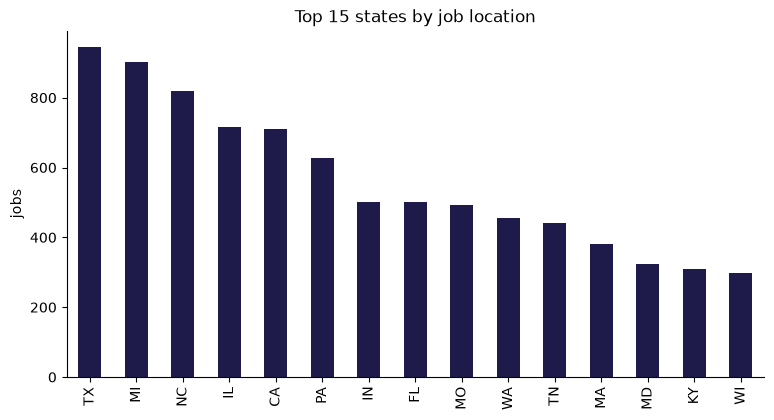

In [11]:
STATES = {"Alabama": "AL", "Alaska": "AK", "Arizona": "AZ", "Arkansas": "AR", "California": "CA", "Colorado": "CO",
          "Connecticut": "CT", "Delaware": "DE", "Florida": "FL", "Georgia": "GA", "Hawaii": "HI", "Idaho": "ID",
          "Illinois": "IL", "Indiana": "IN", "Iowa": "IA", "Kansas": "KS", "Kentucky": "KY", "Louisiana": "LA",
          "Maine": "ME", "Maryland": "MD", "Massachusetts": "MA", "Michigan": "MI", "Minnesota": "MN",
          "Mississippi": "MS", "Missouri": "MO", "Montana": "MT", "Nebraska": "NE", "Nevada": "NV",
          "New Hampshire": "NH", "New Jersey": "NJ", "New Mexico": "NM", "New York": "NY", "North Carolina": "NC",
          "North Dakota": "ND", "Ohio": "OH", "Oklahoma": "OK", "Oregon": "OR", "Pennsylvania": "PA",
          "Rhode Island": "RI", "South Carolina": "SC", "South Dakota": "SD", "Tennessee": "TN", "Texas": "TX",
          "Utah": "UT", "Vermont": "VT", "Virginia": "VA", "Washington": "WA", "West Virginia": "WV",
          "Wisconsin": "WI", "Wyoming": "WY"}
CODES = set(STATES.values()) | {"DC"}
NAMES = re.compile(r"\b(" + "|".join(sorted(STATES, key=len, reverse=True)) + r")\b", re.I)
CODE = re.compile(r"(?:^|,\s*|-\s*)([A-Za-z]{2})(?=\s*(?:$|,|-))")

def job_state(location):
    if pd.isna(location):
        return None
    codes = [c.upper() for c in CODE.findall(location) if c.upper() in CODES]
    if codes:
        return codes[0]
    names = NAMES.findall(location)
    return STATES[names[-1].title()] if names else None

jobs["job_state"] = jobs["location"].map(job_state)
print(f"State found for {jobs['job_state'].notna().mean():.0%} of jobs")
print(f"Of those, {(jobs['job_state'] != jobs['system_state'])[jobs['job_state'].notna()].mean():.0%} are outside the system's home state")
ax = jobs["job_state"].value_counts().head(15).plot.bar(color="#1e1b4b")
ax.set_title("Top 15 states by job location"); ax.set_ylabel("jobs"); ax.set_xlabel("")
plt.show()

A state could be read for 68% of jobs, and about a third of those (32%) are outside the system's home state,
so don't use `system_state` as a job's location. The chart undercounts wherever postings name only a city or a
hospital. California is the clearest case, with locations such as "Sacramento" and "San Francisco" left blank.

## The full data

This sample is one week of postings. The full, nightly-updated data, filterable by role, unit, shift, per diem /
travel, sign-on bonus, state and pay, is the [US Hospital & Nurse Jobs](https://apify.com/viridian_layout_ea2/us-hospital-jobs)
Actor on Apify.